# 05. 학습한 인공신경망을 ESP32에 넣기 — 환경 부담 점수로 신호등 켜기
03번에서 학습한 상태 분류 MLP(입력 8 → 16 → 8 → 출력 3)의 가중치를 C 헤더 파일(`model_weights.h`)로 바꾼다.

장치는 신경망 출력을 '상태 이름'으로 바로 쓰지 않고, **환경 부담 점수 = 1 − P(최적)** 으로 바꿔 쓴다. 이 점수를 약 3분 동안 부드럽게(지수이동평균) 만든 뒤
- 점수 < 0.4 → **초록(양호)**, 0.4 이상 → **노랑(주의)**, 0.7 이상 → **빨강(경고)**

이렇게 하면 소음·조도·CO₂를 따로 나눠 판단하지 않고 **모든 센서를 한꺼번에 본 신경망 계산 하나**로 단계를 정할 수 있고, 라벨에 '졸림'이 없어도 세 단계를 표현할 수 있다. 원인(CO₂·조도·소음 등)은 화면 설명용으로 따로 보여 준다.

**검증:** 장치의 C 코드와 똑같은 계산(z-점수 → 행렬곱 → ReLU → 행렬곱 → ReLU → 행렬곱 → 가장 큰 값)을 32비트 실수로 다시 해서, 파이썬 모델의 예측과 **모든 기록에서 같은지** 확인한다.

In [1]:
import os, sys, numpy as np, pandas as pd, joblib
from common import *
sys.path.insert(0, os.path.join(ROOT, "tools"))
from export_mlp import FEATURES

pack = joblib.load(f"{PROC}/state_mlp8.joblib"); m, sc = pack["model"], pack["scaler"]
assert [f[2:] for f in pack["feats"]] == FEATURES, "특징 순서가 펌웨어와 다름"
W = [np.asarray(w, np.float64) for w in m.coefs_]; B = [np.asarray(b, np.float64) for b in m.intercepts_]

# 펌웨어 출력은 항상 3칸(0=최적, 1=졸림, 2=산만). 학습에 없던 상태는 절대 고르지 않도록 편향을 아주 작게 둔다.
cls = list(m.classes_)
if len(cls) == 2 and W[2].shape[1] == 1:          # 이진 분류: 출력 1개(로짓) → 두 칸으로 펼침
    W[2] = np.hstack([-W[2] / 2, W[2] / 2]); B[2] = np.array([-B[2][0] / 2, B[2][0] / 2])
W3 = np.zeros((W[2].shape[0], 3)); B3 = np.full(3, -1e4)
for j, c in enumerate(cls): W3[:, c] = W[2][:, j]; B3[c] = B[2][j]
W[2], B[2] = W3, B3
print("학습된 상태:", [STATE_KO[c] for c in cls], "| 층 크기:", [w.shape for w in W])

학습된 상태: ['최적', '산만'] | 층 크기: [(8, 16), (16, 8), (8, 3)]


In [2]:
def cf(x):                                        # C 실수 표기 (정수 모양이면 .0 을 붙여야 f 접미사가 유효)
    s = f"{x:.7g}"
    return (s if any(ch in s for ch in ".en") else s + ".0") + "f"
def arr1(n, v): return f"const float {n}[{len(v)}] = {{{', '.join(cf(x) for x in v)}}};\n"
def arr2(n, M):
    rows = ",\n  ".join("{" + ", ".join(cf(x) for x in r) + "}" for r in M)
    return f"const float {n}[{M.shape[0]}][{M.shape[1]}] = {{\n  {rows}\n}};\n"
std = np.where(sc.scale_ == 0, 1.0, sc.scale_)
path = os.path.join(ROOT, "firmware/classroom_env/model_weights.h")
with open(path, "w", encoding="utf-8") as f:
    f.write("// 자동 생성 파일 — analysis/05_export_to_esp32.py\n// 입력 순서: " + ", ".join(FEATURES) + "\n#pragma once\n")
    f.write(f"#define MLP_IN {W[0].shape[0]}\n#define MLP_H1 {W[0].shape[1]}\n#define MLP_H2 {W[1].shape[1]}\n#define MLP_OUT 3\n")
    f.write(arr1("MLP_MEAN", sc.mean_) + arr1("MLP_STD", std))
    for k in range(3): f.write(arr2(f"MLP_W{k+1}", W[k].T) + arr1(f"MLP_B{k+1}", B[k]))
print("저장:", path, f"({os.path.getsize(path)/1024:.1f} KB)")

저장: /home/claude/repo/firmware/classroom_env/model_weights.h (4.4 KB)


## 검증: 장치 계산 = 파이썬 모델?

In [3]:
lab = pd.read_csv(f"{PROC}/labeled.csv", encoding="utf-8-sig").dropna(subset=pack["feats"])
X = lab[pack["feats"]].to_numpy()
f32 = np.float32
z = ((X - sc.mean_) / std).astype(f32)
h = np.maximum(0, z @ W[0].astype(f32) + B[0].astype(f32))
h = np.maximum(0, h @ W[1].astype(f32) + B[1].astype(f32))
dev = np.argmax(h @ W[2].astype(f32) + B[2].astype(f32), axis=1)
py = m.predict(sc.transform(lab[pack["feats"]]))
print(f"비교한 기록 {len(X):,}개 중 예측이 같은 기록: {(dev == py).sum():,}개 ({(dev == py).mean()*100:.2f}%)")

비교한 기록 690개 중 예측이 같은 기록: 690개 (100.00%)


## 환경 부담 점수와 단계 기준 정하기
학습에 쓰지 않은 라벨 구간에 대한 점수(라벨 하나씩 빼서 학습한 모델의 점수)를 시간 순서로 이어 붙이고, 장치와 같은 지수이동평균(10초마다 5%)을 적용했다. 부드럽게 하기 전후의 구분력(AUC)과, 실제 상태별로 신호등이 어떤 색이 되는지 확인한다.

구분력 AUC — 부드럽게 하기 전 0.686 → 지수이동평균 후 0.715
       실제 최적 실제 산만
초록(양호)   61%   42%
노랑(주의)   11%    7%
빨강(경고)   28%   52%


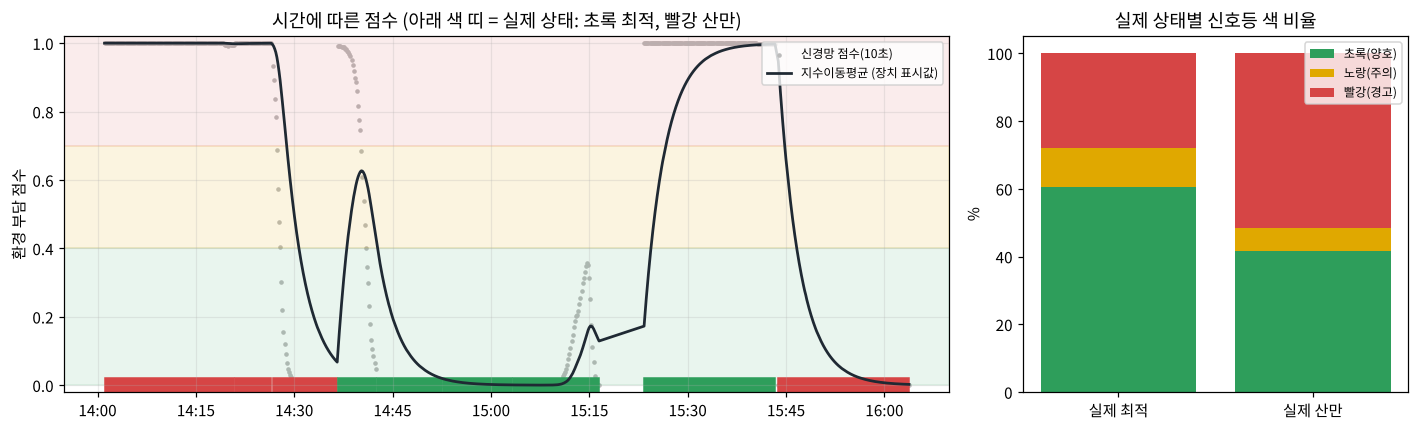

In [4]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
L = lab.sort_values("ts").reset_index(drop=True)
yy = L["state_label"].to_numpy(); gg = L["group"].to_numpy(); F = pack["feats"]
raw = np.zeros(len(L))
for tr, te in LeaveOneGroupOut().split(L, yy, gg):
    mm = make_pipeline(StandardScaler(), MLPClassifier((16, 8), activation="relu", alpha=1e-2, max_iter=2000, random_state=0)).fit(L[F].iloc[tr], yy[tr])
    raw[te] = 1 - mm.predict_proba(L[F].iloc[te])[:, list(mm.classes_).index(0)]
ema = pd.Series(raw).ewm(alpha=0.05, adjust=False).mean().to_numpy()
print(f"구분력 AUC — 부드럽게 하기 전 {roc_auc_score(yy == 2, raw):.3f} → 지수이동평균 후 {roc_auc_score(yy == 2, ema):.3f}")
WARN, ALERT = 0.4, 0.7
lv = np.where(ema >= ALERT, 2, np.where(ema >= WARN, 1, 0))
tab = pd.DataFrame({s_: [(lv[yy == s_] == k).mean() for k in range(3)] for s_ in sorted(np.unique(yy))}, index=["초록(양호)", "노랑(주의)", "빨강(경고)"])
tab.columns = [f"실제 {STATE_KO[c]}" for c in tab.columns]
print((tab * 100).round(0).astype(int).astype(str).add("%").to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.3, 1]})
t = pd.to_datetime(L["ts"], unit="s", utc=True).dt.tz_convert("Asia/Seoul")
ax[0].scatter(t, raw, s=4, color="#bbb", label="신경망 점수(10초)")
ax[0].plot(t, ema, color="#1f2933", lw=1.8, label="지수이동평균 (장치 표시값)")
ax[0].axhspan(0, WARN, color="#2e9e5b", alpha=.10); ax[0].axhspan(WARN, ALERT, color="#e0a800", alpha=.12); ax[0].axhspan(ALERT, 1.02, color="#d64545", alpha=.10)
for gi, gdf in L.groupby("group"):
    ax[0].axvspan(pd.to_datetime(gdf.ts.min(), unit="s", utc=True).tz_convert("Asia/Seoul"), pd.to_datetime(gdf.ts.max(), unit="s", utc=True).tz_convert("Asia/Seoul"),
                  ymin=0, ymax=.04, color=STATE_COLOR[int(gdf.state_label.iloc[0])])
import matplotlib.dates as md
ax[0].xaxis.set_major_formatter(md.DateFormatter("%H:%M", tz="Asia/Seoul")); ax[0].set_ylim(-.02, 1.02)
ax[0].set_ylabel("환경 부담 점수"); ax[0].set_title("시간에 따른 점수 (아래 색 띠 = 실제 상태: 초록 최적, 빨강 산만)"); ax[0].legend(loc="upper right", fontsize=8); ax[0].grid(alpha=.25)
bottom = np.zeros(tab.shape[1])
for k, col in enumerate(["#2e9e5b", "#e0a800", "#d64545"]):
    ax[1].bar(tab.columns, tab.iloc[k] * 100, bottom=bottom, color=col, label=tab.index[k]); bottom += tab.iloc[k].to_numpy() * 100
ax[1].set_ylabel("%"); ax[1].set_title("실제 상태별 신호등 색 비율"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES}/05_score_levels.png", dpi=150); plt.show()

## 장치의 점수 계산 검증
장치 코드와 같은 32비트 실수로 소프트맥스까지 계산한 점수가 파이썬 모델의 점수와 같은지 확인한다.

In [5]:
o = h @ W[2].astype(f32) + B[2].astype(f32)
o = np.exp(o - o.max(axis=1, keepdims=True)); dev_score = 1 - o[:, 0] / o.sum(axis=1)
py_score = 1 - m.predict_proba(sc.transform(lab[pack["feats"]]))[:, list(m.classes_).index(0)]
print(f"점수 최대 차이: {np.abs(dev_score - py_score).max():.2e} (32비트 실수 반올림 수준이면 같은 계산)")

점수 최대 차이: 2.32e-07 (32비트 실수 반올림 수준이면 같은 계산)
